<a href="https://colab.research.google.com/github/nmhom/MAT-422/blob/main/MAT422_HW_3.5%2C3.6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HW 3.5, 3.6

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 3.5: K-means

K-means splits data into $k$ groups (clusters). Each point belongs to the cluster whose center (mean) is closest to it.

The goal is to make the points in each cluster as close to their center as possible. This is measured by the within-cluster sum of squares (WCSS):

$$WCSS_i = \sum_{x \in S_i} \|x - \mu(S_i)\|^2$$

where $\mu(S_i)$ is the mean of the points in cluster $S_i$.

**Algorithm:**
1. Pick $k$ starting centers.
2. Assign each point to its closest center.
3. Move each center to the mean of its points.
4. Repeat steps 2–3 until nothing changes.

Round 1  WCSS = 33.87
Round 2  WCSS = 3.33
Round 3  WCSS = 3.33
Round 4  WCSS = 3.33


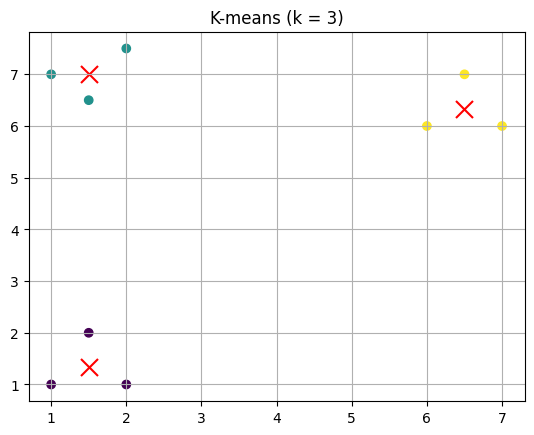

In [ ]:
# 9 points that form 3 groups
X = np.array([[1, 1], [1.5, 2], [2, 1],
              [6, 6], [6.5, 7], [7, 6],
              [1, 7], [1.5, 6.5], [2, 7.5]])

centers = X[[0, 3, 4]]   # use 3 data points as starting centers

for r in range(4):
    # assign each point to the closest center
    labels = np.argmin(np.linalg.norm(X[:, None] - centers, axis=2), axis=1)
    # move each center to the mean of its points
    centers = np.array([X[labels == i].mean(axis=0) for i in range(3)])
    # total WCSS
    wcss = np.sum((X - centers[labels])**2)
    print("Round", r + 1, " WCSS =", round(wcss, 2))

plt.scatter(X[:, 0], X[:, 1], c=labels)
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="x", s=150)
plt.title("K-means (k = 3)")
plt.grid()
plt.show()

K-means found the 3 groups. The WCSS goes down and then stays the same, which shows the algorithm converges. K-means only finds a local optimum, though, so a bad choice of starting centers can give a worse answer.

### Why the center is the mean

The text shows the mean is the point that makes WCSS smallest (set the derivative to zero and solve). To check, I compare the WCSS at the mean of the cluster to the WCSS at a nearby point.

In [ ]:
cluster = X[labels == 0]
mean = cluster.mean(axis=0)

print("WCSS at mean:      ", round(np.sum((cluster - mean)**2), 2))
print("WCSS at mean + 0.5:", round(np.sum((cluster - (mean + 0.5))**2), 2))

WCSS at mean:       1.17
WCSS at mean + 0.5: 2.67


Moving away from the mean makes the WCSS bigger, so the mean is the best center.

## 3.6: Support Vector Machine

An SVM separates two classes ($y = 1$ and $y = -1$) with a line

$$w^T x - b = 0$$

and makes the gap between the classes as wide as possible. The gap width is $2/\|2\|$, so a smaller $\|w\|$ means a wider gap.

The SVM minimizes

$$\lambda\|w\|^2 + \frac{1}{n}\sum_{i=1}^{n}\max\{0,\ 1 - y_i(w^T x_i - b)\}$$

The first part makes the gap wide. The second part (the hinge loss) is 0 when a point is on the correct side of the gap and positive when it isn't. This function is convex, so we can use stochastic gradient descent.

**SGD update** (pick one point $i$ at random):
- If $1 - y_i(w^T x_i - b) > 0$: $\ w \leftarrow w - \beta(2\lambda w - y_i x_i)$ and $b \leftarrow b - \beta y_i$
- Otherwise: $\ w \leftarrow w - \beta(2\lambda w)$

w = [0.42209953 0.30101893]  b = 3.00999999999998
Predictions: [-1. -1. -1. -1.  1.  1.  1.  1.]


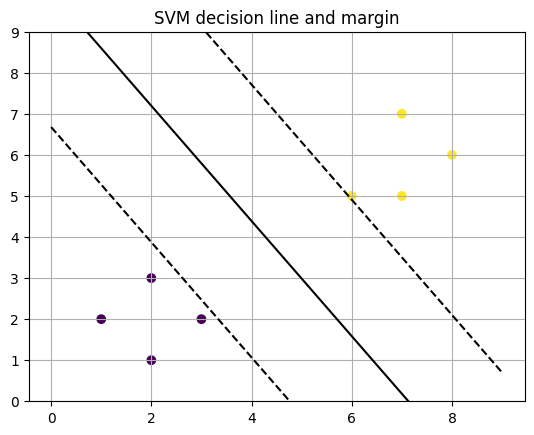

In [ ]:
# two classes of points
X_svm = np.array([[1, 2], [2, 3], [2, 1], [3, 2],
                  [6, 5], [7, 7], [8, 6], [7, 5]], dtype=float)
y = np.array([-1, -1, -1, -1, 1, 1, 1, 1])

rng = np.random.default_rng(0)
w = np.zeros(2)
b = 0.0
beta = 0.01   # step size
lam = 0.01    # lambda

for step in range(5000):
    i = rng.integers(len(y))
    if 1 - y[i] * (X_svm[i] @ w - b) > 0:
        w = w - beta * (2 * lam * w - y[i] * X_svm[i])
        b = b - beta * y[i]
    else:
        w = w - beta * (2 * lam * w)

print("w =", w, " b =", b)
print("Predictions:", np.sign(X_svm @ w - b))

# plot the line w^T x - b = 0 (solid) and the gap edges (dashed)
x1 = np.linspace(0, 9, 100)
plt.plot(x1, (b - w[0] * x1) / w[1], "k")
plt.plot(x1, (1 + b - w[0] * x1) / w[1], "k--")
plt.plot(x1, (-1 + b - w[0] * x1) / w[1], "k--")
plt.scatter(X_svm[:, 0], X_svm[:, 1], c=y)
plt.ylim(0, 9)
plt.title("SVM decision line and margin")
plt.grid()
plt.show()

All 8 points are classified correctly. The solid line separates the classes, and the dashed lines are the edges of the gap. To classify a new point, check the sign of $w^T x - b$.

In [ ]:
new_points = np.array([[3, 3], [6, 6]])
print("Predicted classes:", np.sign(new_points @ w - b))

Predicted classes: [-1.  1.]
